# Tutorial 8: Measuring the impact of a retracted paper

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/melhzy/pubmed-stream/blob/main/tutorials/08_retraction_impact.ipynb) Run it in your browser with nothing to install, or on your own computer: [how to run the tutorials](guides/setup.md).

In 2006, *Nature* published **"A specific amyloid-β protein assembly in the brain impairs memory"** (Lesné and colleagues, [PMID 16541076](https://pubmed.ncbi.nlm.nih.gov/16541076/)). It reported **Aβ\*56**, an assembly of amyloid-β that impaired memory in mice, and it became one of the most cited papers in Alzheimer's disease research. In July 2022 an investigation in *Science* raised concerns about manipulated images in it, and *Nature* added an editor's note. In June 2024 the paper was **retracted**, with all authors except the first agreeing ([retraction notice, PMID 38914864](https://pubmed.ncbi.nlm.nih.gov/38914864/)).

A retraction removes a paper from the record, but not the papers built on it. This tutorial measures how far the paper reached, and how the papers citing it use it.

## In brief

From the saved run, on 18 October 2026:

- **It reached one in seven Alzheimer's papers.** 1,240 papers in PubMed cite it, and 44,921 more cite one of those: together, 15,039 of the 107,302 Alzheimer's disease papers in PubMed since 2006.
- **Most papers cite it for a general idea.** Of the 756 citing papers whose citing sentence could be read, 590 cite it for a general statement about amyloid-β oligomers and memory; 157 name Aβ\*56.
- **Few say it is in doubt.** 74 papers cite it from 2022 on; only 9 of them mention the retraction or the doubts where they cite it.
- **The work built on it is still growing.** Citations of the paper peaked in 2012, but papers citing its citers still grow, to about 4,000 a year.
- **Retractions cluster.** 6 papers citing it have been retracted too, 4 of them with the same first author.

The sections below show how each number is measured, with a chart for each, and build a knowledge graph to explore in Obsidian. The same notebook measures any other paper if you change the settings. Words such as MeSH, PMC or stub are explained in the [glossary](guides/glossary.md).

**Time:** about 15 minutes, mostly to download the full text of the citing papers (about 100 MB). A free NCBI API key makes it about three times faster.

## Your settings

This is the only cell you need to edit. To study another paper, change the PubMed ID, its DOI, a few words of its title, and the words that name its specific finding. For a paper that was not retracted, leave the two dates empty.

In [1]:
SEED = "16541076"                 # PubMed ID of the paper: A specific amyloid-beta protein assembly in the brain impairs memory
SEED_DOI = "10.1038/nature04533"  # its DOI, to find it in reference lists
TITLE_WORDS = "specific amyloid"  # a few words of its title, for references without a DOI
FINDING = "Aβ*56"                 # a short name for its specific finding, for the charts
FINDING_WORDS = ["Aβ*56", "Abeta*56", "A beta*56", "Aβ56", "Abeta56", "56-kDa", "56 kDa"]   # how authors write it
DOUBTS_PUBLIC = "2022-07"         # year and month doubts about the paper became public, or ""
RETRACTED = "2024-06"             # year and month it was retracted, or ""
FIELD = "Alzheimer Disease"       # the MeSH heading of its field, to put its reach in proportion
SECOND_HOP_SEEDS = 10             # citing papers whose own neighborhoods join the knowledge graph
NCBI_API_KEY = ""   # optional: paste your free NCBI key between the quotes to run about three times faster

In [2]:
# Setup: run this cell as it is. In Google Colab it first fetches the tutorial files.
import os
import re
import subprocess
import sys

if "google.colab" in sys.modules:
    if not os.path.isdir("/content/pubmed-stream"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/melhzy/pubmed-stream.git", "/content/pubmed-stream"], check=True)
    sys.path.insert(0, "/content/pubmed-stream/tutorials")

import pandas as pd

import tutorial_utils as tu

tu.setup("retraction_impact", api_key=NCBI_API_KEY)
tu.style()
pd.set_option("display.max_colwidth", 200)

import citation_impact as ci
import impact_charts as charts
from pubmed_stream import create_kg, download_neighborhood, get_neighborhood

finding = re.compile("|".join(re.escape(w) for w in FINDING_WORDS), re.I)
KINDS = [ci.KINDS[0], f"Names {FINDING}", ci.KINDS[2], ci.KINDS[3]]
COLOURS = dict(zip(KINDS, [tu.ORANGE, tu.BLUE, tu.AQUA, tu.GREY]))
EVENTS = [(int(d[:4]) - 0.5 + (int(d[5:7]) - 1) / 12, f"{pd.Timestamp(d + '-01'):%b %Y}\n{label}")
          for d, label in [(DOUBTS_PUBLIC, "doubts published"), (RETRACTED, "retracted")] if d]

## 1. The paper and its notices

`get_neighborhood` fetches the paper with **every** paper PubMed links to it: here up to 5,000 citing papers instead of the usual 100. PubMed also links the notices published about a paper: its retraction, corrections and comments.

In [3]:
hood = get_neighborhood(SEED, max_per_relation=5000)
seed = hood.seed
first_year = int(seed.year)
print(f"{seed.title}\n{', '.join(seed.authors)}\n{seed.journal}, {seed.year}. Retracted: {seed.is_retracted}")
pd.DataFrame(ci.corrections(SEED))

A specific amyloid-beta protein assembly in the brain impairs memory.
Lesné Sylvain, Koh Ming Teng, Kotilinek Linda, Kayed Rakez, Glabe Charles G, Yang Austin, Gallagher Michela, Ashe Karen H
Nature, 2006. Retracted: True


,type,pmid,source
0,Comment In,16541054,Nature. 2006 Mar 16;440(7082):284-5. doi: 10.1038/440284a.
1,Retraction In,38914864,Nature. 2024 Jul;631(8019):240. doi: 10.1038/s41586-024-07691-8.


## 2. How far did it reach?

The **neighbors** are the papers that cite it. The **neighbors' neighbors** are the papers that cite one of those: they may never cite the retracted paper themselves, but they build on work that does. PubMed answers both questions with its citation links, a hundred papers per request, so this cell takes two or three minutes. It also counts the papers of the paper's field, to put the reach in proportion.

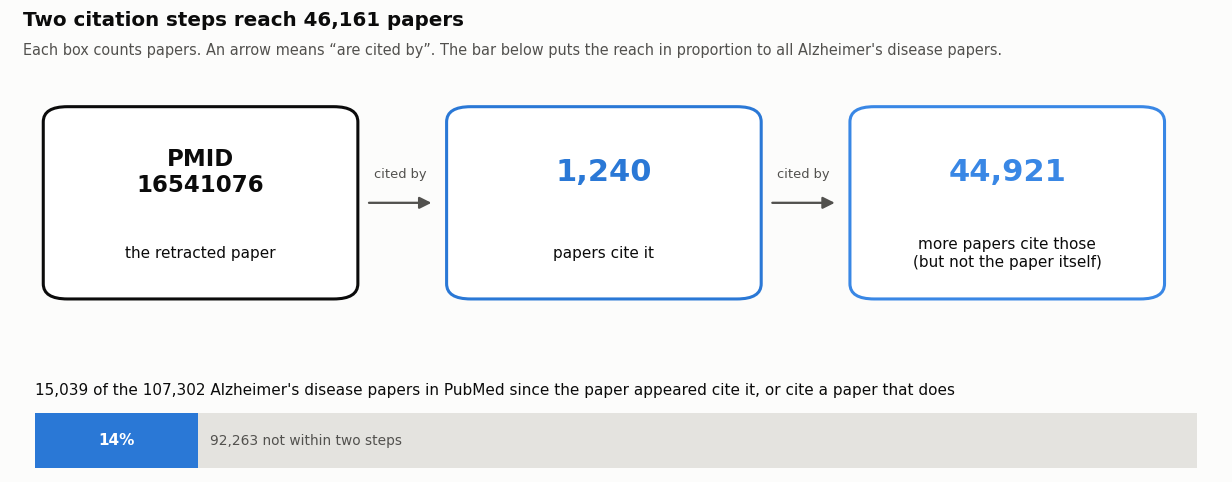

In [4]:
hop1 = {a.pmid for a in hood.cited_by}
citers = ci.citers_of(sorted(hop1))
hop2 = set().union(*citers.values()) - hop1 - {SEED}
field_total = ci.pubmed_count(f'"{FIELD}"[mh] AND {first_year}:3000[dp]')
field_near = ci.count_matching(hop1 | hop2, {"field": f'"{FIELD}"[mh]'})["field"]

charts.reach(f"PMID\n{SEED}", len(hop1), len(hop2), field_total, field_near, FIELD.replace(" Disease", "'s disease"))

The second step is an upper bound on influence, not a measure of harm: a paper that cites a broad review of amyloid-β, which happens to cite the retracted paper, counts too. Section 4 narrows it down by reading how each paper cites it.

## 3. When was it cited?

PubMed's citation links come from articles deposited in PubMed Central, so they count fewer citations than Google Scholar or Web of Science, and the current year is incomplete; its bars are paler.

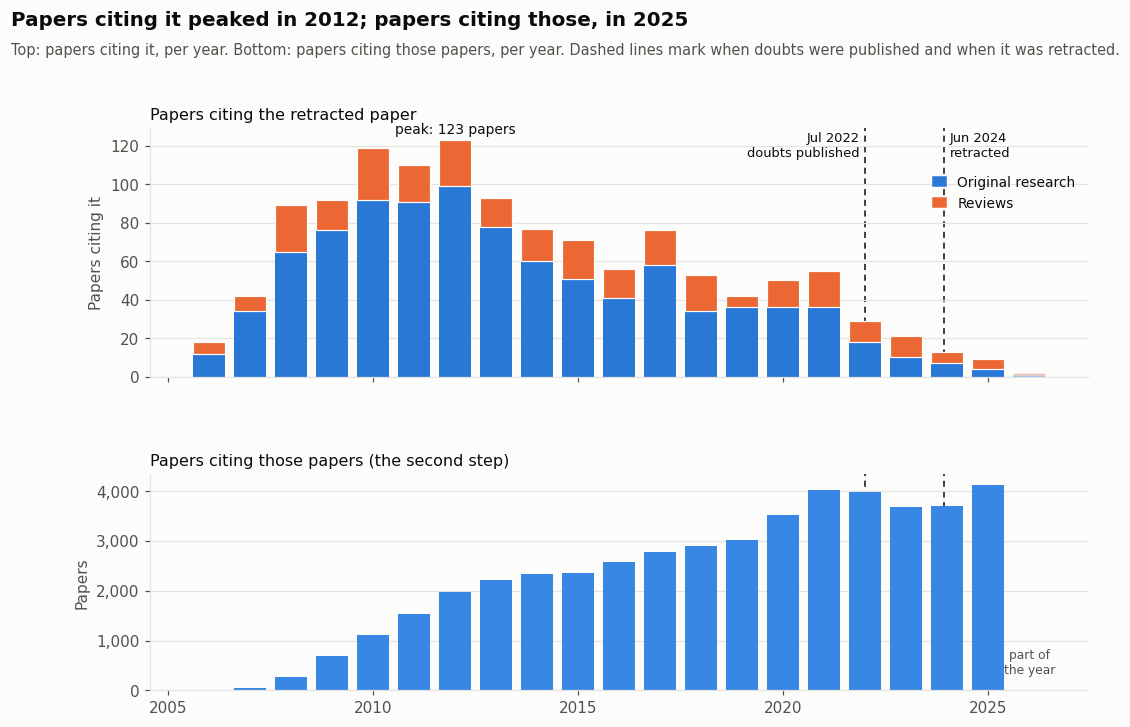

In [5]:
cited_by = pd.DataFrame([{"pmid": a.pmid, "year": int(a.year), "review": a.is_review, "retracted": a.is_retracted,
                          "pmcid": a.pmcid, "title": a.title, "authors": a.authors}
                         for a in hood.cited_by if a.year and a.year.isdigit()])
last_year = int(cited_by["year"].max())
years = list(range(first_year, last_year + 1))
per_year = (cited_by.groupby(["year", "review"]).size().unstack(fill_value=0)
            .reindex(index=years, columns=[False, True], fill_value=0))
hop2_years = ci.count_by_year(hop2, first_year, last_year)

charts.timeline(years, list(per_year[False]), list(per_year[True]), hop2_years, EVENTS,
                partial=pd.Timestamp.today().year)

## 4. How was it cited?

A citation count says nothing about **why** a paper was cited. Was it the evidence for a key step in the argument, one of many references for a general statement, or an example of a problem? The full text answers that.

The next cell downloads the full text of every citing paper in PubMed Central, as XML. In XML each citation is marked, so `ci.citation_contexts` can find the exact sentence that cites the paper, even inside a range such as [10–14]. `ci.classify` then sorts each citing paper by its sentences, in this order:

| Kind | The sentence citing the paper... | Colour |
|---|---|---|
| **Discusses the retraction or doubts** | mentions the retraction, manipulated data or images, fabrication, an editor's note, concerns about the paper, or a failure to reproduce it | orange |
| **Names Aβ\*56** | names the specific finding, with one of `FINDING_WORDS` | blue |
| **Cites it in general** | supports a general statement, such as "soluble oligomers impair memory" | aqua |
| **No full text, or citation not found** | could not be read: the paper is not in PubMed Central, its publisher withholds the full text, or the citing sentence could not be found, for instance because it is in a table | grey |

The classification uses keywords, so it makes mistakes: read the examples below before you trust the counts.

In [6]:
with tu.quiet():
    stats = download_neighborhood(hood, output_dir="fulltext", fmt="xml", include_text=False)
contexts = ci.citation_contexts(stats.output_dir, SEED, SEED_DOI, TITLE_WORDS, finding=finding)
by_pmid = {c["pmid"]: c for c in contexts.values() if c["pmid"]}

def kind_of(pmid):
    kind = ci.classify(by_pmid.get(pmid, {}).get("sentences", []), finding)
    return f"Names {FINDING}" if kind == ci.KINDS[1] else kind

cited_by["kind"] = cited_by["pmid"].map(kind_of)
cited_by["sentence"] = cited_by["pmid"].map(lambda p: " … ".join(by_pmid.get(p, {}).get("sentences", [])))
cited_by["mentions"] = cited_by["pmid"].map(lambda p: by_pmid.get(p, {}).get("mentions"))
print(f"Full text downloaded: {stats.successful + stats.skipped} of {stats.requested} articles in PubMed Central; "
      f"{stats.unavailable} withheld by their publishers")
cited_by["kind"].value_counts().reindex(KINDS, fill_value=0).to_frame("citing papers")

Full text downloaded: 832 of 1207 articles in PubMed Central; 375 withheld by their publishers


,citing papers
kind,
Discusses the retraction or doubts,9
Names Aβ*56,157
Cites it in general,590
"No full text, or citation not found",484


The chart counts only the papers that could be read, so that the grey ones do not hide the others; the right edge says how many each period has.

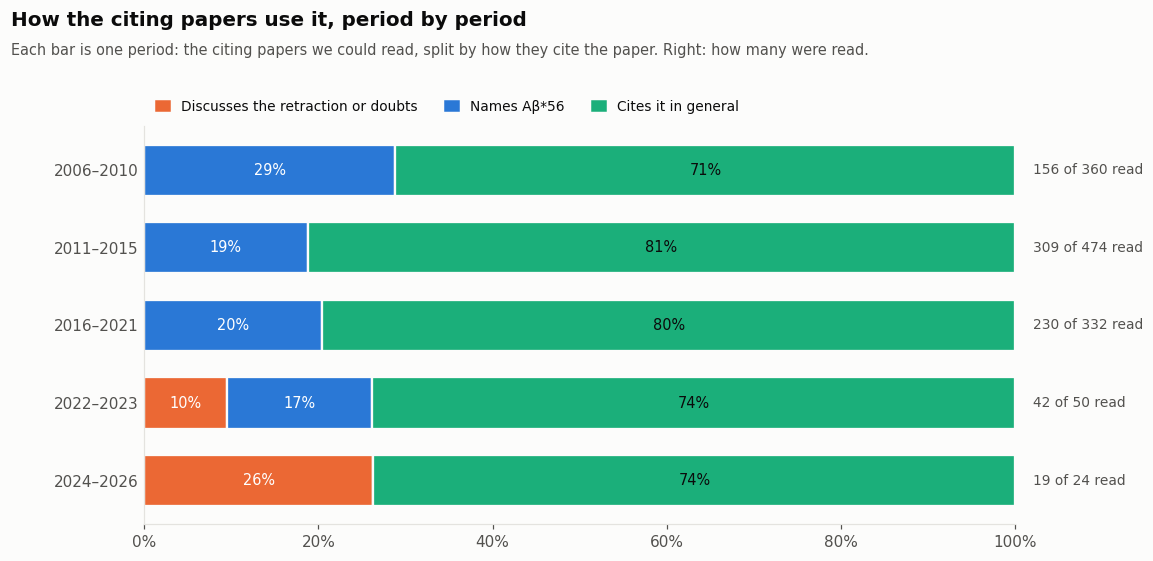

In [7]:
edges = [first_year, 2011, 2016] + [int(d[:4]) for d in (DOUBTS_PUBLIC, RETRACTED) if d] + [last_year + 1]
edges = sorted(set(e for e in edges if first_year <= e <= last_year + 1))
periods = [f"{a}–{b - 1}" if b - 1 > a else str(a) for a, b in zip(edges, edges[1:])]
cited_by["period"] = pd.cut(cited_by["year"], edges, right=False, labels=periods)
read = cited_by[cited_by["kind"] != KINDS[3]]
counts = {p: read[read["period"] == p]["kind"].value_counts().to_dict() for p in periods}
unread = cited_by[cited_by["kind"] == KINDS[3]]["period"].value_counts().to_dict()

charts.kinds_by_period(periods, counts, unread, KINDS[:3], COLOURS, "How the citing papers use it, period by period")

Read a few sentences of each kind. They show what the paper was used for, and whether the classification is right. **⟦CITE⟧** marks the place where the sentence cites the retracted paper; the other numbers are its other references.

In [8]:
examples = (read.sort_values("year", ascending=False).groupby("kind").head(3).sort_values(["kind", "year"]))
examples[["kind", "year", "pmid", "sentence"]].assign(sentence=examples["sentence"].map(lambda s: tu.short(s, 300)))

,kind,year,pmid,sentence
2,Cites it in general,2025,41624198,"The amyloid-beta (Aβ) hypothesis proposes that soluble Aβ oligomers (SO-Aβ) are major drivers of synaptic dysfunction and neuronal injury (⟦CITE⟧, 3)."
11,Cites it in general,2025,39422790,"However, it is unclear whether AD pathogenesis is driven by non-fibrillar Aβ multimers or amyloid plaques [97, ⟦CITE⟧]."
4,Cites it in general,2025,40413393,"In an extreme example, post-publication peer review and “sleuthing” successfully identified serious errors in Alzheimer’s disease research [⟦CITE⟧, 6], but more than a decade after the original pu..."
14,Discusses the retraction or doubts,2024,39121130,"The hypothesis was that a specific amyloid-β (Aβ) protein assembly, Aβ*56, blocks memory.⟦CITE⟧ … As a result, the article was retracted by Nature on March 16, 2024 and most of the authors agreed ..."
7,Discusses the retraction or doubts,2025,39996369,"Candidates have included dimers,51 dodecamers52 (note: the initial 2006 study identifying dodecamers⟦CITE⟧ was recently retracted due to data manipulation), and even a heterogeneous “oligomeric so..."
3,Discusses the retraction or doubts,2025,41227148,"Chistian Piller, journalist at e-Science, documented several examples of this scientific pressure: the retraction of an influential article published in 2006 in Nature [⟦CITE⟧,96] about the role o..."
58,Names Aβ*56,2022,35557606,"Size exclusion chromatography (SEC) analysis of these AβO solutions revealed a predominant peak eluting shortly before the 43 kDa standard, likely corresponding to the 56 kDa dodecamer identified ..."
55,Names Aβ*56,2022,35885050,"Three oligomeric structures amyloid-β trimers, Aβ*56 and amyloid-β dimers—have been identified in AD mouse models and humans [40,⟦CITE⟧]."
33,Names Aβ*56,2023,37216514,Concentrations of Aβ trimers are elevated in cognitively normal adults who are at risk for Alzheimer’s disease (⟦CITE⟧). … Aβ trimers appear to be the building blocks of the putative dodecamer of ...


In [9]:
never = (read["mentions"] == 0).sum()
print(f"{never} of the {len(read)} citing papers that could be read ({never / len(read):.0%}) never mention "
      f"{FINDING} anywhere in their text: they cite the paper for a broader claim.")

578 of the 756 citing papers that could be read (76%) never mention Aβ*56 anywhere in their text: they cite the paper for a broader claim.


## 5. Cited after the doubts and the retraction

A citation after a retraction is not always an error: a paper may cite it to discuss the retraction. The chart shows every paper citing it since doubts became public, one square each; the table lists them, newest first.

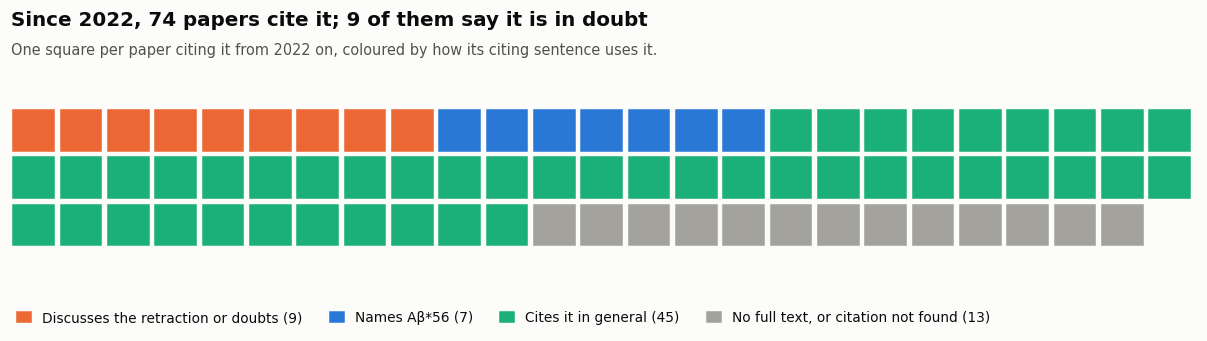

,year,pmid,kind,title
0,2026,42624989,"No full text, or citation not found",Targeting soluble misfolded oligomers in anti-amyloid research.
1,2026,42066286,"No full text, or citation not found",Performance of AI Tools in Citing Retracted Literature : Content Analysis.
2,2025,41624198,Cites it in general,Unraveling the neuroprotective mechanisms of elephant black garlic extract against beta a…
3,2025,41227148,Discusses the retraction or doubts,"Alzheimer Syndrome or Age-Related Dementia-History, Therapy and Prevention."
4,2025,40413393,Cites it in general,"""Non-Markovian"" and ""directional"" errors inhibit scientific self-correction and can lead…"
...,...,...,...,...
74,2022,35038191,Cites it in general,The amyloid concentric β-barrel hypothesis: Models of amyloid beta 42 oligomers and annul…
76,2022,34896392,Names Aβ*56,Aptamers targeting amyloidogenic proteins and their emerging role in neurodegenerative di…
79,2022,34878720,Cites it in general,Rational Design of a Cu Chelator That Mitigates Cu-Induced ROS Production by Amyloid Beta.
81,2022,34810230,"No full text, or citation not found",Presenilin/γ-Secretase Activity Is Located in Acidic Compartments of Live Neurons.


In [10]:
since = int((DOUBTS_PUBLIC or RETRACTED or str(last_year))[:4])
late = cited_by[cited_by["year"] >= since].sort_values("year", ascending=False)
doubting = (late["kind"] == KINDS[0]).sum()
charts.waffle(list(late.sort_values("year")["kind"]), KINDS, COLOURS,
              f"Since {since}, {len(late)} papers cite it; {doubting} of them say it is in doubt",
              f"One square per paper citing it from {since} on, coloured by how its citing sentence uses it.")
late[["year", "pmid", "kind", "title"]].assign(title=late["title"].map(lambda t: tu.short(t, 90)))

## 6. Retracted papers that cite it

Retractions cluster: when one paper falls, papers by the same authors, or built on the same data, are often examined too. PubMed flags each citing paper that has itself been retracted. The last column lists the authors it shares with the retracted paper, matched by last name and first initial, because PubMed writes "Lesné Sylvain" in one record and "Lesné Sylvain E" in another.

In [11]:
def person(name):
    parts = name.split()
    return (parts[0], parts[1][:1]) if len(parts) > 1 else (name, "")

seed_people = {person(n) for n in seed.authors}
retracted = cited_by[cited_by["retracted"]].copy()
retracted["shared_authors"] = retracted["authors"].map(lambda names: ", ".join(n for n in names if person(n) in seed_people))
retracted["their_citers"] = retracted["pmid"].map(lambda p: len(citers.get(p, [])))
retracted[["year", "pmid", "title", "kind", "their_citers", "shared_authors"]].sort_values("year")

,year,pmid,title,kind,their_citers,shared_authors
915,2010,20655472,SIRT1 suppresses beta-amyloid production by activating the alpha-secretase gene ADAM10.,Cites it in general,209,
981,2011,20031278,Cognitive effects of cell-derived and synthetically derived Aβ oligomers.,Names Aβ*56,71,"Lesné Sylvain, Ashe Karen H"
682,2012,22836259,Soluble α-synuclein is a novel modulator of Alzheimer's disease pathophysiology.,"No full text, or citation not found",79,Lesné Sylvain E
651,2012,23175838,The complex PrP(c)-Fyn couples human oligomeric Aβ with pathological tau changes in Alzheimer's disease.,"No full text, or citation not found",174,Lesné Sylvain E
316,2017,28487416,The amyloid-β oligomer Aβ*56 induces specific alterations in neuronal signaling that lead to tau phosphorylation and aggregation.,Names Aβ*56,60,Lesné Sylvain E
163,2020,32246090,In situ structural characterization of early amyloid aggregates in Alzheimer's disease transgenic mice and Octodon degus.,Names Aβ*56,3,


## 7. Where did its influence travel?

Some citing papers carried the paper much further than others: a widely cited review reaches thousands of readers. The first chart ranks the citing papers by how many papers cite **them**.

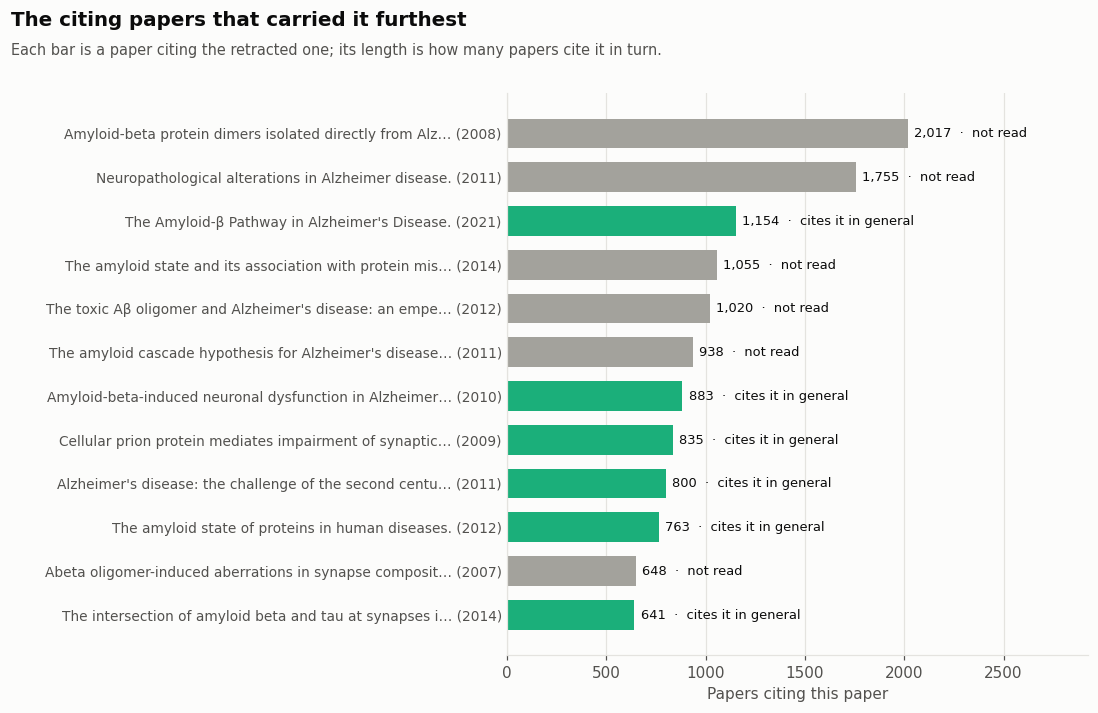

In [12]:
cited_by["their_citers"] = cited_by["pmid"].map(lambda p: len(citers.get(p, [])))
top = cited_by.nlargest(12, "their_citers")
charts.carriers([f"{tu.short(t, 55)} ({y})" for t, y in zip(top["title"], top["year"])], list(top["their_citers"]),
                list(top["kind"]), COLOURS, "The citing papers that carried it furthest")

The second chart follows every second-step paper back to the paper it cites. Each one is counted once, by its most specific link: a paper citing both a paper that names Aβ\*56 and a review that cites it in general counts as building on Aβ\*56.

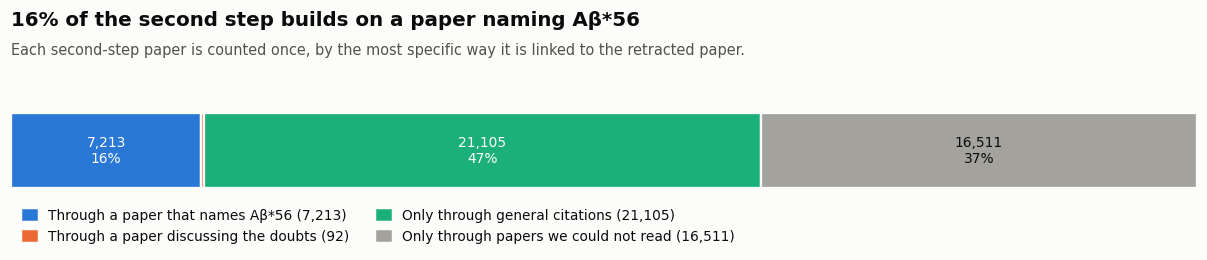

In [13]:
via = {}
for kind in [KINDS[1], KINDS[0], KINDS[2], KINDS[3]]:   # most specific first
    for pmid in cited_by.loc[cited_by["kind"] == kind, "pmid"]:
        for q in citers.get(pmid, []):
            if q in hop2:
                via.setdefault(q, kind)
labels = {KINDS[1]: f"Through a paper that names {FINDING}", KINDS[0]: "Through a paper discussing the doubts",
          KINDS[2]: "Only through general citations", KINDS[3]: "Only through papers we could not read"}
parts = [(labels[k], sum(1 for v in via.values() if v == k), COLOURS[k]) for k in [KINDS[1], KINDS[0], KINDS[2], KINDS[3]]]
charts.composition(parts, len(hop2), f"{parts[0][1] / len(hop2):.0%} of the second step builds on a paper naming {FINDING}",
                   "Each second-step paper is counted once, by the most specific way it is linked to the retracted paper.")

## 8. Compared with its neighbors

Is that much reach unusual? The papers PubMed finds most **similar** to the retracted one are a fair comparison: same topic, similar methods.

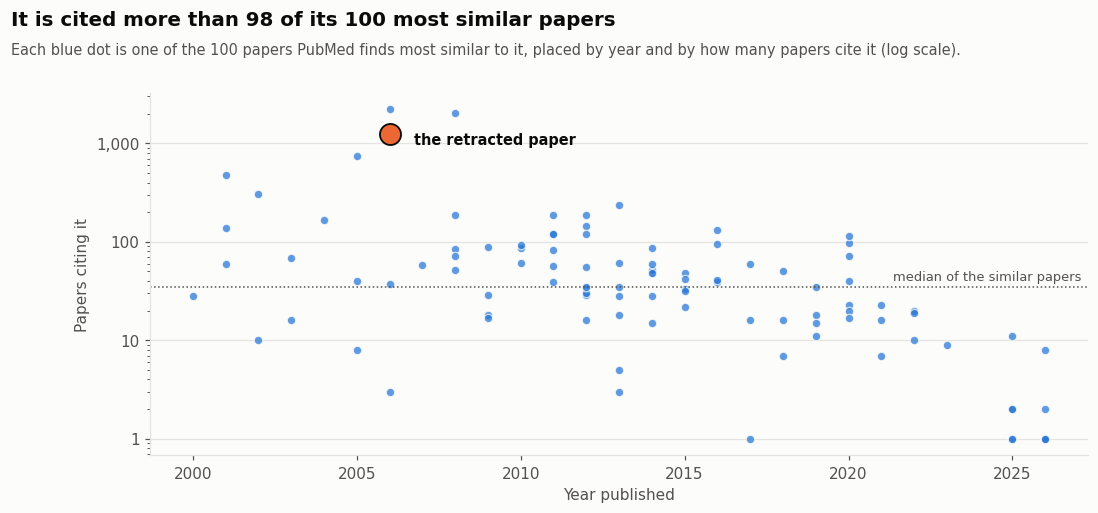

In [14]:
similar_citers = ci.citers_of([a.pmid for a in hood.similar])
similar = pd.DataFrame([{"year": int(a.year), "citations": len(similar_citers.get(a.pmid, []))}
                        for a in hood.similar if a.year and a.year.isdigit()])
beaten = (similar["citations"] < len(hop1)).sum()
charts.compared(list(similar["year"]), list(similar["citations"]), first_year, len(hop1), "the retracted paper",
                f"It is cited more than {beaten} of its {len(similar)} most similar papers")

## 9. A knowledge graph of the paper's impact

Everything above becomes an Obsidian knowledge graph in two steps:

1. The retracted paper's neighborhood: every paper citing it and the 100 most similar papers, each a note with its MeSH topics and flags.
2. The neighborhoods of some citing papers, their **neighbors' neighbors**: the retracted citing papers, then the most-cited papers that name Aβ\*56, up to `SECOND_HOP_SEEDS`, with 30 similar, citing and cited papers each.

Then each citing paper's note gets three properties of its own: `hop`, `citation_kind`, and `citation_sentence`, the sentence that cites the paper. Obsidian shows them on each note, and a table, **Citation impact.base**, lists the citing papers by kind. Rebuilding the graph keeps them.

In [15]:
TOPIC = "abeta56 retraction impact"
with tu.quiet():
    result = create_kg(TOPIC, seeds=[SEED], max_per_relation=5000)
    named = cited_by[cited_by["kind"] == f"Names {FINDING}"].nlargest(SECOND_HOP_SEEDS, "their_citers")
    second_seeds = list(dict.fromkeys(list(retracted["pmid"]) + list(named["pmid"])))[:SECOND_HOP_SEEDS]
    result = create_kg(TOPIC, seeds=second_seeds, max_per_relation=30)
print(result)

properties = {SEED: {"hop": 0}}
for row in cited_by.itertuples():
    sentence = row.sentence.replace(ci.CITE, f"[PMID {SEED}]")
    properties[row.pmid] = {"hop": 1, "citation_kind": row.kind, "citation_sentence": tu.short(sentence, 400)}
for pmid in hop2:
    properties.setdefault(pmid, {"hop": 2})
print("Notes annotated:", ci.annotate(result.kg_dir, properties))
print("Table:", ci.write_base(result.kg_dir).name)


Knowledge graph: abeta56 retraction impact
Folder:            workspace\retraction_impact\kg_abeta56_retraction_impact
Study searches:    0 (0 run now, 0 new articles)
Study seeds:       11 (10 fetched now)
Obsidian vault
Vault:             workspace\retraction_impact\kg_abeta56_retraction_impact
Sources:           11
Papers:            2008 (0 full text, 2008 stubs)
MeSH concepts:     2389
Collections:       11
Notes:             1134 created, 964 updated, 2311 unchanged
PubMed records:    86 fetched
  - Without MeSH:  278 (offline, too new, or a journal outside MEDLINE)


Notes annotated: 1682
Table: Citation impact.base


A map of the graph: the papers citing the retracted one around it, grouped by kind, and the neighborhoods fetched in step 2 fanned out around their papers.

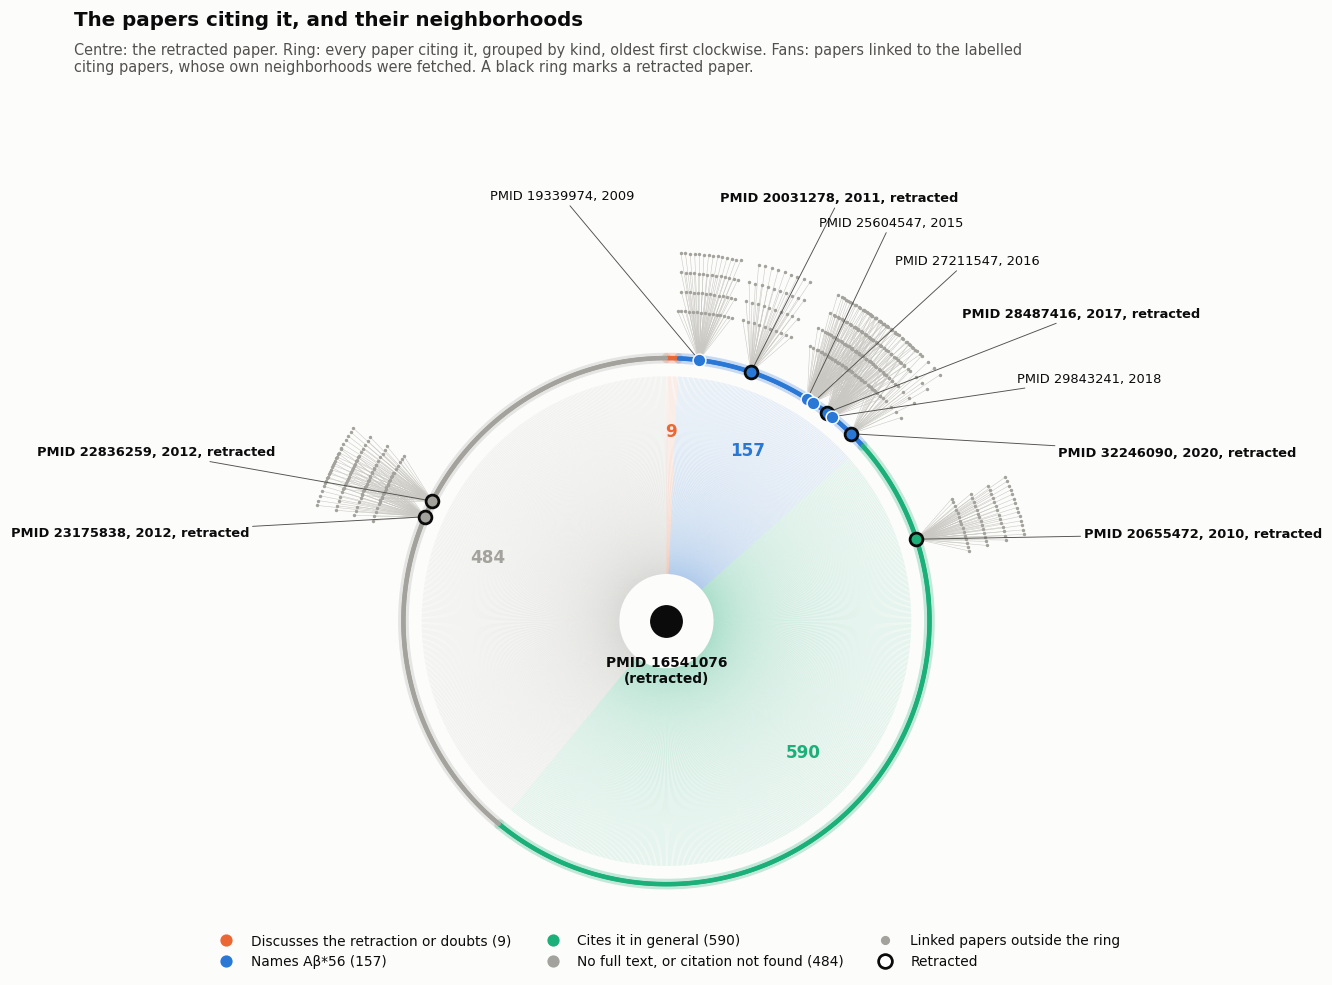

In [16]:
kg = tu.read_kg(result.kg_dir)
charts.radial_map(kg, SEED, dict(zip(cited_by["pmid"], cited_by["kind"])), KINDS, COLOURS, second_seeds,
                  "The papers citing it, and their neighborhoods")

**Open it in Obsidian.** Choose **Open folder as vault** and select the folder printed above, `kg_abeta56_retraction_impact`; the [Obsidian guide](guides/obsidian.md) explains the rest. Then:

- Open **Citation impact** for the table of citing papers, one view per kind: you can read every citing sentence there, sort by year, and add your own columns.
- Open the retracted paper's note, `PMID16541076`, to see every paper citing it, and its retraction flag.
- Search `[citation_kind: "Discusses the retraction or doubts"]` to find the papers that discuss the retraction.

![The Citation impact table in Obsidian, showing the papers that discuss the retraction, with the sentence in which each one cites it](guides/images/obsidian-citation-impact.png)

In Google Colab, the next cell saves the graph to your computer as a zip file. A copy of the graph from the saved run is also in the repository, in [`knowledge_graphs/kg_abeta56_retraction_impact`](knowledge_graphs/README.md): download it to explore the graph without running this notebook.

In [17]:
if tu.in_colab():
    tu.download(result.kg_dir)

## 10. At a glance

The headline numbers of this run, for a slide or a report.

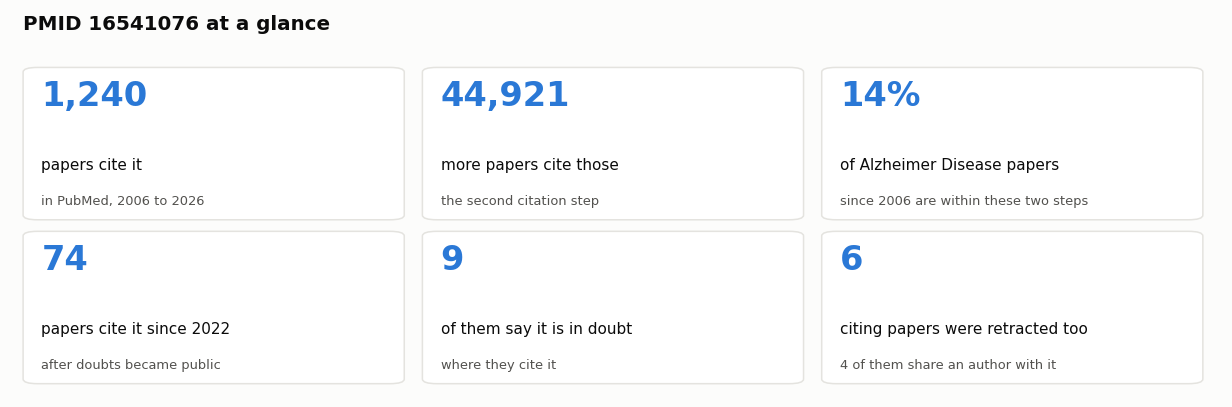

In [18]:
late_since = f"since {since}"
charts.key_numbers([
    (f"{len(hop1):,}", "papers cite it", f"in PubMed, {first_year} to {last_year}"),
    (f"{len(hop2):,}", "more papers cite those", "the second citation step"),
    (f"{field_near / field_total:.0%}", f"of {FIELD} papers", f"since {first_year} are within these two steps"),
    (f"{len(late)}", f"papers cite it {late_since}", "after doubts became public" if DOUBTS_PUBLIC else "recently"),
    (f"{doubting}", "of them say it is in doubt", "where they cite it"),
    (f"{len(retracted)}", "citing papers were retracted too",
     f"{(retracted['shared_authors'] != '').sum()} of them share an author with it"),
], f"PMID {SEED} at a glance")

## 11. What these numbers can and cannot tell you

- **The counts are PubMed's.** PubMed links a citation only when the citing article's full text is in PubMed Central, so it counts fewer citations than Google Scholar or Web of Science: 1,240 here, where nearly 2,500 have been reported for this paper. The shares and trends are more reliable than the totals.
- **The second step is an upper bound.** A paper two steps away may share nothing with Aβ\*56 beyond a common review. Section 7 shows how much of the reach passes through papers that name the finding.
- **The classification is by keywords.** "Controversy" may refer to the amyloid hypothesis in general rather than this paper, and a paper can discuss Aβ\*56 without the words in `FINDING_WORDS`. Read the sentences, in section 4 or in Obsidian, before you report a number.
- **A citation is not an endorsement.** Papers cite work to build on it, to compare with it, or to dispute it, and only the sentence tells which.
- **Retractions take time to spread.** PubMed marks the retracted paper, but citing papers written before the retraction stay as they are, and reviews keep their claims until they are revised.

To study another paper, change the settings at the top and run the notebook again. For a paper that has not been retracted, the same sections measure how its finding spread, and whether anyone has questioned it.

**Next:** [tutorial 4](04_evidence_neighborhood.ipynb) explains evidence neighborhoods, and [tutorial 5](05_knowledge_graph.ipynb) the knowledge graph, in more depth.